<a href="https://colab.research.google.com/github/telloudi-khadijaencg-alt/23009059-TELLOUDIKHADIJA-G3FINANCE/blob/main/notebooks/projet_F21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# F21 : Force du dollar

**Nom et prénom :** Telloudi Khadija    **Code Apogée :** 23009059    **Groupe :** G3FINANCE    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/telloudi-khadijaencg-alt/23009059-TELLOUDIKHADIJA-G3FINANCE

## 1. Sujet et problématique
- **Intérêt du sujet :** Le dollar influence les coûts d'importation, les exportations et la valeur des actifs internationaux, donc les entreprises exportatrices, les investisseurs et les banques centrales suivent son évolution. Un modèle qui anticipe son rendement du mois suivant pourrait aider à décider de la couverture du risque de change.
- **Problématique :** Les rendements passés du dollar permettent-ils de prévoir son rendement du mois suivant mieux qu'une règle naïve ?
- **Objectif mesurable :** RMSE sur le test inférieur d'au moins 2 % à celui de la moyenne d'apprentissage, test de 2020 à la dernière donnée.
- **Nature du problème :** régression sur série temporelle.
- **Algorithme principal envisagé :** n°2 (Ridge)

In [20]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, sys
GRAINE = 42
np.random.seed(GRAINE)
print(sys.version, sklearn.__version__, pd.__version__)

3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0] 1.6.1 2.2.3


## 2. Jeu de données

- **Source :** FRED (Federal Reserve Bank of St. Louis), série DTWEXBGS, indice nominal large du dollar américain.
- **URL :** https://fred.stlouisfed.org/series/DTWEXBGS
- **Date d'extraction :** 17/11/2026
- **Licence :** (écris ce que dit la page FRED de la série ; si rien n'est indiqué, écris « non précisée »)
- **Taille et période :** ... observations, du ... au ..., fréquence quotidienne (jours ouvrés)
- **Unité d'observation :** un jour ouvré, puis un mois après agrégation en fin de mois
- **Variable cible :** rendement mensuel du mois suivant, en % (`cible`)
- **Adéquation :** la série couvre le dollar contre un panier large de monnaies pondéré par le commerce, ce qui permet d'étudier sa force globale.
- **Limites :** période courte (depuis 2006), une seule grande phase de dollar fort, chocs de 2008 et 2020 qui peuvent changer le régime, jours fériés manquants, série éventuellement révisée.

In [21]:
URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DTWEXBGS"
Path("data/raw").mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(URL, index_col=0, parse_dates=True)
raw.to_csv("data/raw/DTWEXBGS.csv")
raw = pd.read_csv("data/raw/DTWEXBGS.csv", index_col=0, parse_dates=True)
raw.columns = ["indice"]
raw["indice"] = pd.to_numeric(raw["indice"], errors="coerce")

print(raw.shape, raw.index.min(), raw.index.max())
print(raw.isna().sum())
print(raw.describe())
print(raw.head())

(5445, 1) 2006-01-02 00:00:00 2026-11-13 00:00:00
indice    214
dtype: int64
            indice
count  5231.000000
mean    106.558713
std      12.366974
min      85.469200
25%      93.803650
50%     110.303400
75%     117.299750
max     130.041300
                    indice
observation_date          
2006-01-02        101.4155
2006-01-03        100.7558
2006-01-04        100.2288
2006-01-05        100.2992
2006-01-06        100.0241


| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| indice | Niveau de l'indice large du dollar | numérique | points d'indice | brute | ... |
| r | Rendement mensuel = 100 × variation du log de l'indice fin de mois | numérique | % | explicative (retardée) | ... |
| r_lag1, r_lag2, r_lag3 | Rendements des 1, 2 et 3 mois précédents | numérique | % | explicative | ... |
| vol3 | Écart-type des rendements sur 3 mois, jusqu'à t | numérique | % | explicative | ... |
| mom12 | Somme des rendements sur 12 mois, jusqu'à t | numérique | % | explicative | ... |
| cible | Rendement du mois suivant (r décalé de −1) | numérique | % | cible | ... |

**Interprétation.** Le jeu contient 5 445 observations quotidiennes (jours ouvrés), du 2 janvier 2006 au 13 novembre 2026, soit environ 21 ans de données. La série comporte 214 valeurs manquantes (3,9 %), qui correspondent aux jours fériés où le marché est fermé et que FRED laisse vides. Je ne les supprime pas à ce stade : en prenant la dernière valeur de chaque mois, ces trous disparaissent, car chaque mois contient au moins un jour de cotation. L'indice varie entre 85,5 et 130,0 points, avec une moyenne de 106,6 et un écart-type de 12,4, ce qui montre que le dollar a connu de longues phases de hausse et de baisse sur la période. La période étant courte (environ 250 rendements mensuels), il faut rester prudent sur la complexité du modèle et sur la portée des conclusions.

In [22]:
m = raw["indice"].resample("ME").last().dropna()   # dernière valeur de chaque mois
m = m[m.index < "2026-11-01"]                       # on retire novembre 2026 (incomplet)

df = pd.DataFrame({"r": np.log(m).diff() * 100})    # rendement mensuel en %
for k in (1, 2, 3):
    df[f"r_lag{k}"] = df["r"].shift(k)              # rendements des mois précédents
df["vol3"] = df["r"].rolling(3).std()               # volatilité sur 3 mois, jusqu'à t
df["mom12"] = df["r"].rolling(12).sum()             # somme des rendements sur 12 mois
df["cible"] = df["r"].shift(-1)                     # rendement du mois SUIVANT
df = df.dropna()

print(df.shape)
print(df.head())
print(df.tail())

(237, 7)
                         r    r_lag1    r_lag2    r_lag3      vol3     mom12  \
observation_date                                                               
2007-01-31        0.956749  0.468264 -0.837463 -0.731785  0.927607 -1.486488   
2007-02-28       -0.743231  0.956749  0.468264 -0.837463  0.875240 -2.569477   
2007-03-31       -0.950942 -0.743231  0.956749  0.468264  1.046610 -4.309623   
2007-04-30       -1.550398 -0.950942 -0.743231  0.956749  0.419128 -3.425290   
2007-05-31       -0.544520 -1.550398 -0.950942 -0.743231  0.506017 -3.591374   

                     cible  
observation_date            
2007-01-31       -0.743231  
2007-02-28       -0.950942  
2007-03-31       -1.550398  
2007-04-30       -0.544520  
2007-05-31       -0.193356  
                         r    r_lag1    r_lag2    r_lag3      vol3     mom12  \
observation_date                                                               
2026-05-31        0.174532 -1.972480  2.690220 -0.065586  2.333778 

In [23]:
from google.colab import files
files.download("data/raw/DTWEXBGS.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

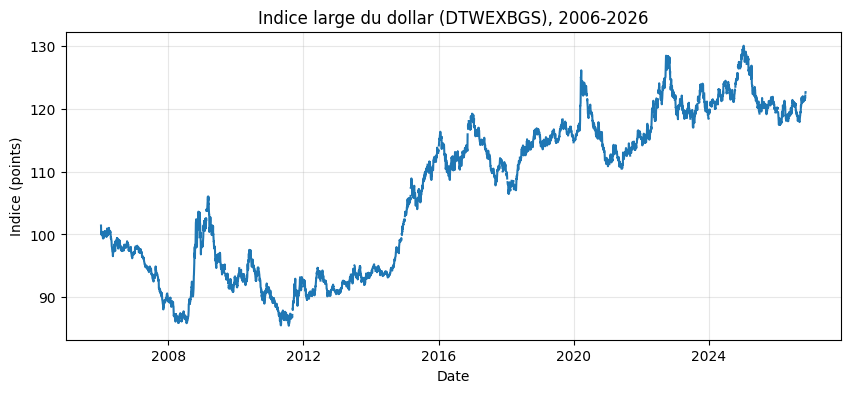

In [24]:
Path("figures").mkdir(exist_ok=True)
plt.figure(figsize=(10, 4))
plt.plot(raw.index, raw["indice"])
plt.title("Indice large du dollar (DTWEXBGS), 2006-2026")
plt.xlabel("Date")
plt.ylabel("Indice (points)")
plt.grid(alpha=0.3)
plt.savefig("figures/graph1_indice.png", dpi=150, bbox_inches="tight")
plt.show()


**Interprétation.** L'indice large du dollar évolue entre 85 et 130 points sur 2006-2026. On distingue de longues phases : une baisse de 2006 à 2008 (vers 86 points), une pointe brutale fin 2008-début 2009 liée à la crise financière, un point bas vers 2011, puis une forte hausse de 2014 à 2016 (jusqu'à environ 115). Le niveau monte ensuite par paliers, avec une nouvelle pointe en 2020 (choc du Covid) et un sommet proche de 130 points en 2022-2025. La série n'oscille pas autour d'une valeur fixe : son niveau dérive dans le temps, donc elle n'est pas stationnaire. Je ne modélise donc pas le niveau, mais les rendements mensuels, qui sont plus stables et comparables d'une période à l'autre.

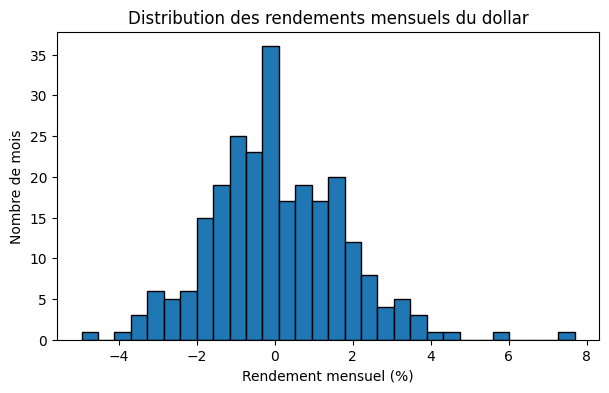

count    249.000000
mean       0.081049
std        1.725122
min       -4.951767
25%       -1.015185
50%       -0.106071
75%        1.226214
max        7.694817
Name: indice, dtype: float64
observation_date
2008-10-31    7.694817
2011-09-30    5.848052
2009-05-31    4.951767
Name: indice, dtype: float64


In [25]:
m_exp = raw["indice"].resample("ME").last()
m_exp = m_exp[m_exp.index < "2026-11-01"]
r_exp = np.log(m_exp).diff() * 100

plt.figure(figsize=(7, 4))
plt.hist(r_exp.dropna(), bins=30, edgecolor="black")
plt.title("Distribution des rendements mensuels du dollar")
plt.xlabel("Rendement mensuel (%)")
plt.ylabel("Nombre de mois")
plt.savefig("figures/graph2_rendements.png", dpi=150, bbox_inches="tight")
plt.show()

print(r_exp.describe())
print(r_exp.abs().sort_values(ascending=False).head(3))

**Interprétation.** Les 249 rendements mensuels forment une distribution à peu près symétrique et centrée autour de 0 %, la plupart des mois se situant entre -2 % et +2 %. Cela montre que le dollar varie peu d'un mois à l'autre et qu'il n'y a pas de tendance mensuelle nette. Quelques mois extrêmes se détachent, de l'ordre de -5 % à +8 %, donc la distribution a des queues un peu plus lourdes qu'une loi normale. Ces valeurs correspondent à de vrais épisodes de tension sur les marchés, donc je les conserve : les supprimer ferait disparaître justement les situations que le modèle doit apprendre à gérer. Il faudra en revanche les garder à l'esprit en analysant les erreurs, car la RMSE y est sensible.

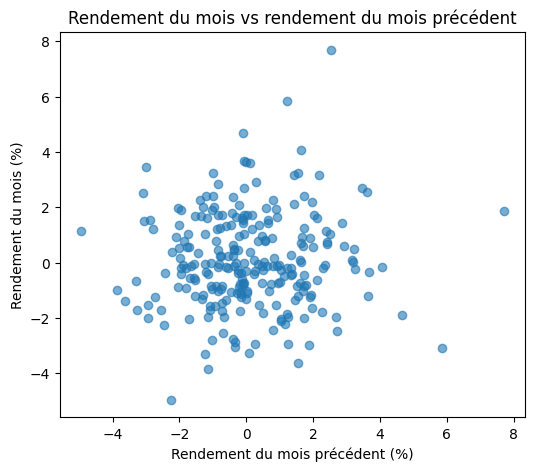

Corrélation : 0.04381638210197474


In [26]:
d = pd.concat([r_exp.shift(1), r_exp], axis=1).dropna()
d.columns = ["r_prec", "r"]

plt.figure(figsize=(6, 5))
plt.scatter(d["r_prec"], d["r"], alpha=0.6)
plt.title("Rendement du mois vs rendement du mois précédent")
plt.xlabel("Rendement du mois précédent (%)")
plt.ylabel("Rendement du mois (%)")
plt.savefig("figures/graph3_nuage.png", dpi=150, bbox_inches="tight")
plt.show()

print("Corrélation :", d["r_prec"].corr(d["r"]))

**Interprétation.** Les points forment un nuage sans forme, sans pente visible, et la corrélation entre le rendement d'un mois et celui du mois précédent est de 0,044, c'est-à-dire pratiquement nulle. Le rendement du mois passé n'apporte donc quasiment aucune information sur celui du mois suivant, ce qui est cohérent avec l'idée que le taux de change se rapproche d'une marche aléatoire. Je m'attends donc à ce que le modèle ait du mal à battre la référence naïve, et un résultat proche de la référence, voire légèrement moins bon, serait un résultat honnête et interprétable. Quelques points isolés (rendements supérieurs à 5 % en valeur absolue) correspondent aux mois extrêmes déjà repérés et sont conservés.

**Qualité des données.**
- **Valeurs manquantes :** 214 jours sur 5 445 (3,9 %), détectés avec `isna().sum()`. Ce sont des jours fériés sans cotation. Décision : je prends la dernière valeur de chaque mois, donc aucun mois n'est vide et il n'y a pas d'imputation.
- **Doublons :** aucune date répétée, car la série est indexée par date. (Vérifie avec `raw.index.duplicated().sum()`, le résultat doit être 0.)
- **Valeurs atypiques :** détectées par le tri des rendements mensuels en valeur absolue. Les plus extrêmes correspondent à de vrais épisodes de marché. Décision : je les conserve, car ce ne sont pas des erreurs, et je les analyserai dans l'étude des erreurs.

In [27]:
print("Doublons de dates :", raw.index.duplicated().sum())

Doublons de dates : 0


In [28]:
from google.colab import files
for f in ["graph1_indice.png", "graph2_rendements.png", "graph3_nuage.png"]:
    files.download("figures/" + f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
features = ["r", "r_lag1", "r_lag2", "r_lag3", "vol3", "mom12"]

train = df[:"2019-11-30"]        # apprentissage : janvier 2007 à novembre 2019
test = df["2020-01-31":]         # test : janvier 2020 à septembre 2026 (décembre 2019 laissé de côté)

Xtr, ytr = train[features], train["cible"]
Xte, yte = test[features], test["cible"]

print("Apprentissage :", train.index.min().date(), "->", train.index.max().date(), len(train), "mois")
print("Test          :", test.index.min().date(), "->", test.index.max().date(), len(test), "mois")

# Référence naïve : on prédit toujours la moyenne des rendements d'apprentissage
base_pred = np.full(len(yte), ytr.mean())
rmse = lambda a, b: np.sqrt(np.mean((np.array(a) - np.array(b)) ** 2))
print("RMSE référence naïve sur le test :", rmse(yte, base_pred))

Apprentissage : 2007-01-31 -> 2019-11-30 155 mois
Test          : 2020-01-31 -> 2026-09-30 81 mois
RMSE référence naïve sur le test : 1.612660998849244


## 6. Protocole expérimental

- **Découpage chronologique, sans mélange :** apprentissage de janvier 2007 à novembre 2019 (155 mois), test de janvier 2020 à septembre 2026 (81 mois). Le mois de décembre 2019 est laissé de côté : la cible d'une ligne étant le rendement du mois suivant, cet écart d'un mois empêche que la cible du dernier mois d'apprentissage chevauche le début du test.
- **Référence naïve :** prédire toujours la moyenne des rendements mensuels de l'apprentissage. Elle ne dépend d'aucune variable et représente le meilleur pari sans information.
- **Réglage :** `GridSearchCV` avec `TimeSeriesSplit` (5 plis chronologiques) sur l'apprentissage seulement, pour l'hyperparamètre `alpha` de Ridge, avec 5 valeurs (0,1 ; 1 ; 10 ; 100 ; 1000), soit 5 configurations essayées. La graine est fixée (`GRAINE = 42`).
- **Pipeline :** `StandardScaler` puis `Ridge`. La standardisation est réajustée sur l'apprentissage de chaque pli, ce qui évite toute fuite.
- **Métrique principale :** RMSE (en points de pourcentage), qui pénalise les grosses erreurs, ce qui compte en finance. **Métriques secondaires :** MAE, et taux de bon signe (part des mois où le signe du rendement est bien prédit).
- **Incertitude :** moyenne et écart-type de la RMSE sur les plis de validation.
- **Test :** utilisé **une seule fois**, à la fin, après le choix de `alpha`.
- **Seuil de réussite fixé avant les résultats :** RMSE test au moins 2 % inférieure à celle de la référence, soit ≤ 1,580.

In [30]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe = Pipeline([("sc", StandardScaler()), ("ridge", Ridge())])
grille = {"ridge__alpha": [0.1, 1, 10, 100, 1000]}
tscv = TimeSeriesSplit(n_splits=5)

gs = GridSearchCV(pipe, grille, cv=tscv, scoring="neg_root_mean_squared_error",
                  return_train_score=True)
gs.fit(Xtr, ytr)

res = pd.DataFrame(gs.cv_results_)[["param_ridge__alpha", "mean_train_score",
                                     "mean_test_score", "std_test_score"]]
res[["mean_train_score", "mean_test_score"]] *= -1
res.columns = ["alpha", "RMSE_apprentissage", "RMSE_validation", "ecart_type_validation"]
print(res)
print("Meilleur alpha :", gs.best_params_)

# Référence naïve sur les mêmes plis de validation
rb = []
for a, b in tscv.split(Xtr):
    rb.append(rmse(ytr.iloc[b], np.full(len(b), ytr.iloc[a].mean())))
print("Référence naïve en validation : moyenne", np.mean(rb), "| écart-type", np.std(rb))

    alpha  RMSE_apprentissage  RMSE_validation  ecart_type_validation
0     0.1            1.975908         1.800378               0.224061
1     1.0            1.976312         1.790693               0.218254
2    10.0            1.987457         1.744371               0.198528
3   100.0            2.039534         1.682265               0.199177
4  1000.0            2.077699         1.658595               0.210860
Meilleur alpha : {'ridge__alpha': 1000}
Référence naïve en validation : moyenne 1.654618676698859 | écart-type 0.21340989223352252


**Interprétation du réglage.** La RMSE de validation diminue quand `alpha` augmente, de 1,800 (alpha = 0,1) à 1,659 (alpha = 1000), et le meilleur `alpha` se trouve au bord de la grille. À cette valeur, la pénalité écrase presque tous les coefficients vers zéro : le modèle prédit pratiquement la moyenne des rendements, c'est-à-dire la référence naïve. Celle-ci obtient d'ailleurs 1,655 en validation, contre 1,659 pour Ridge, et l'écart-type entre plis (environ 0,21) est bien supérieur à cette différence. En validation, le modèle n'apporte donc aucun gain mesurable. Cela est cohérent avec la corrélation quasi nulle de 0,044 observée dans l'exploration : le passé du dollar contient très peu d'information sur le mois suivant. Je ne prolonge pas la grille au-delà de 1000, car cela ferait converger le modèle vers la référence sans rien apprendre de plus ; 5 configurations ont été essayées.

                     RMSE       MAE  Taux de bon signe
Référence naïve  1.612661  1.339214            0.45679
Ridge            1.614113  1.342123            0.45679
Amélioration de la RMSE vs référence (%) : -0.09005938696693416
RMSE apprentissage : 1.8221579430601755
r         0.009806
r_lag1    0.009508
r_lag2    0.018505
r_lag3    0.006850
vol3     -0.015858
mom12    -0.009440
dtype: float64


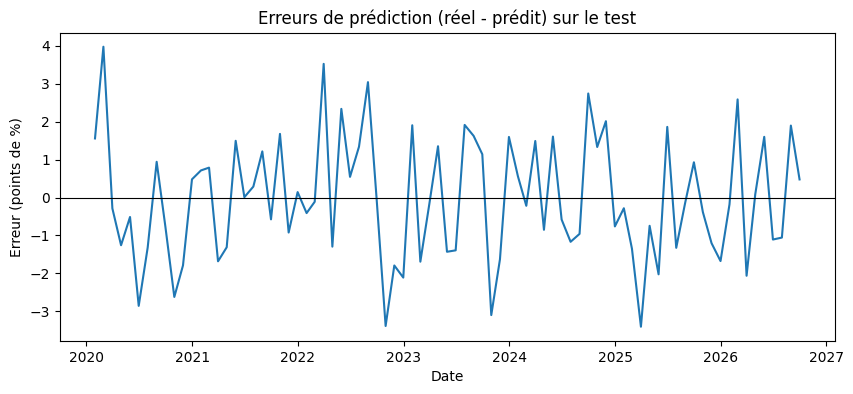

Les 5 plus grosses erreurs :
observation_date
2020-02-29    3.974466
2022-03-31    3.522766
2025-03-31    3.406212
2022-10-31    3.387078
2023-10-31    3.099173
dtype: float64
                      réel    prédit
observation_date                    
2020-01-31        1.647314  0.090936
2021-09-30       -0.441832  0.134065
2023-05-31       -1.336200  0.094229
2025-01-31       -0.157577  0.125729
2026-09-30        0.573950  0.097678


In [31]:
modele = gs.best_estimator_            # Ridge, alpha = 1000, déjà ajusté sur l'apprentissage
pred = modele.predict(Xte)

mae = lambda a, b: np.mean(np.abs(np.array(a) - np.array(b)))
bon_signe = lambda a, b: np.mean(np.sign(np.array(a)) == np.sign(np.array(b)))

tableau = pd.DataFrame({
    "RMSE": [rmse(yte, base_pred), rmse(yte, pred)],
    "MAE": [mae(yte, base_pred), mae(yte, pred)],
    "Taux de bon signe": [bon_signe(yte, base_pred), bon_signe(yte, pred)],
}, index=["Référence naïve", "Ridge"])
print(tableau)
print("Amélioration de la RMSE vs référence (%) :",
      100 * (1 - rmse(yte, pred) / rmse(yte, base_pred)))
print("RMSE apprentissage :", rmse(ytr, modele.predict(Xtr)))

coefs = pd.Series(modele["ridge"].coef_, index=features)
print(coefs)

# Erreurs dans le temps
err = pd.Series(np.array(yte) - pred, index=yte.index)
plt.figure(figsize=(10, 4))
plt.plot(err.index, err)
plt.axhline(0, color="black", lw=0.8)
plt.title("Erreurs de prédiction (réel - prédit) sur le test")
plt.xlabel("Date"); plt.ylabel("Erreur (points de %)")
plt.savefig("figures/graph4_erreurs.png", dpi=150, bbox_inches="tight")
plt.show()
print("Les 5 plus grosses erreurs :")
print(err.abs().sort_values(ascending=False).head(5))

# Illustration sur 5 mois du test
ill = pd.DataFrame({"réel": yte.values, "prédit": pred}, index=yte.index).iloc[[0, 20, 40, 60, 80]]
print(ill)

## 7. Résultats

| Modèle | RMSE test | MAE test | Taux de bon signe |
|---|---|---|---|
| Référence naïve (moyenne d'apprentissage) | 1,6127 | 1,3392 | 45,7 % |
| Ridge (alpha = 1000) | 1,6141 | 1,3421 | 45,7 % |

En validation (5 plis chronologiques), la RMSE vaut 1,659 pour Ridge contre 1,655 pour la référence, avec un écart-type d'environ 0,21 entre plis.

**Interprétation.** Sur le test, Ridge ne fait pas mieux que la référence naïve : sa RMSE est supérieure de 0,09 %, très loin de l'objectif de 2 % d'amélioration. L'objectif mesurable n'est donc pas atteint. Les deux modèles ont le même taux de bon signe (45,7 %) car tous deux prédisent un rendement légèrement positif chaque mois ; ce taux reflète seulement la part de mois positifs dans le test. Les coefficients sont presque nuls (entre -0,016 et 0,019 sur variables standardisées) à cause de la forte pénalité, et leur ordre de grandeur est trop faible pour être interprété : on ne peut conclure à aucun effet, et encore moins à une causalité. La RMSE d'apprentissage (1,82) est supérieure à celle du test (1,61) : il n'y a pas de surapprentissage, et le test semble plus calme que l'apprentissage, qui contient la crise de 2008-2009.

**Analyse des erreurs.** Les erreurs fluctuent autour de zéro sans structure visible dans le temps, ce qui montre que le modèle ne capte aucune dynamique. Les plus grosses (environ 3,1 à 4,0 points) apparaissent aux dates 2020-02-29, 2022-03-31, 2025-03-31, 2022-10-31 et 2023-10-31, la cible étant le rendement du mois suivant : on y retrouve des mois de forte tension, comme mars 2020 avec le choc du Covid. Ces mois imprévisibles expliquent l'essentiel de la RMSE.

**Illustration sur des mois du test (non utilisés pour l'apprentissage).** Par exemple, pour le mois suivant janvier 2020, le rendement réel est de +1,65 % pour une prédiction de +0,09 % ; pour septembre 2021, -0,44 % réel contre +0,13 % prédit ; pour mai 2023, -1,34 % contre +0,09 %. La prédiction reste proche de 0,1 % quel que soit le mois, ce qui confirme que le modèle se comporte comme la moyenne.

## 5. Algorithme : Ridge (n°2)

**Principe.** Ridge est une régression linéaire à laquelle on ajoute une pénalité sur la taille des coefficients. Le modèle prédit le rendement du mois suivant comme une combinaison linéaire des variables, mais les coefficients sont « rétrécis » vers zéro, ce qui réduit leur instabilité quand les variables sont corrélées ou peu informatives, ce qui est le cas ici avec des rendements retardés.

**Formule.** On cherche les paramètres qui minimisent :

Σᵢ (yᵢ − β₀ − xᵢᵀβ)² + α · Σⱼ βⱼ²

- yᵢ : rendement du mois suivant (cible) pour l'observation i ;
- xᵢ : vecteur des variables (r, r_lag1, r_lag2, r_lag3, vol3, mom12), standardisées ;
- β₀ : constante (intercept) ; β : vecteur des coefficients ;
- α ≥ 0 : force de la pénalité.

**Paramètres appris et hyperparamètres.** Les paramètres appris sont β₀ et les βⱼ, estimés sur l'apprentissage. Les hyperparamètres, fixés avant l'apprentissage, sont `alpha`, réglé par validation croisée (grand alpha : coefficients proches de 0 et modèle proche de la moyenne ; petit alpha : proche de la régression linéaire, plus sensible au bruit), et `fit_intercept`, laissé à True car la moyenne des rendements n'est pas nulle.

**Pourquoi Ridge.** Avec 155 mois d'apprentissage et des variables très peu liées à la cible, un modèle simple et régularisé limite le surapprentissage. Je n'ai pas retenu les arbres, forêts ou le gradient boosting : ils ont besoin de plus de données, ne prolongent pas les valeurs au-delà de celles vues à l'apprentissage et risquent d'apprendre le bruit. Une régression linéaire simple (n°1) aurait été plus sensible à la corrélation entre variables ; Ridge est donc une alternative plus stable.

## 8. Analyse critique

- **Limites des données :** période courte (2007-2026, soit 237 mois), peu de crises, changements de régime (2008, 2020), série de niveau pas révisée mais agrégée par mois, ce qui masque la dynamique intra-mensuelle.
- **Limites du protocole :** un seul découpage (test de 81 mois) ; le test inclut le Covid et la période de forte inflation, et les résultats pourraient changer avec une autre période. Seules 5 configurations d'alpha ont été essayées, et le meilleur alpha est au bord de la grille.
- **Biais possibles :** les variables retardées sont peu informatives, et le choix des variables (retards, volatilité, momentum) est limité.
- **Pistes concrètes :** ajouter des variables économiques (écart de taux d'intérêt avec l'étranger, inflation, VIX), tester un horizon plus long (3 ou 6 mois), évaluer plusieurs périodes de test avec une validation glissante, ou prévoir la volatilité du dollar plutôt que son rendement.

## 9. Conclusion

Les rendements passés, la volatilité récente et le momentum ne permettent pas de prévoir le rendement du mois suivant du dollar mieux que la moyenne historique : la RMSE de Ridge sur le test (1,614) est identique à celle de la référence naïve (1,613), soit −0,09 % au lieu des +2 % visés. L'objectif mesurable n'est donc pas atteint. Ce résultat négatif est cohérent avec la corrélation quasi nulle (0,044) entre rendements successifs et avec l'idée qu'un taux de change à un mois est proche d'une marche aléatoire.

In [32]:
from google.colab import files
files.download("figures/graph4_erreurs.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Références et reproduction

- **Données :** Federal Reserve Bank of St. Louis, FRED, série DTWEXBGS (Nominal Broad U.S. Dollar Index), https://fred.stlouisfed.org/series/DTWEXBGS, extraite le 17/11/2026.
- **Bibliothèques :** pandas, NumPy, matplotlib, scikit-learn (documentation officielle).
- **Support de cours :** Tp_ML.ipynb (algorithme n°2, Ridge).
- **Dépôt GitHub :** https://github.com/telloudi-khadijaencg-alt/23009059-TELLOUDIKHADIJA-G3FINANCE
- **Reproduction :** installer Python 3.10 ou plus récent, exécuter `pip install -r requirements.txt`, ouvrir `notebooks/projet_F21.ipynb`, puis « Redémarrer et tout exécuter ». Les données sont téléchargées depuis FRED puis enregistrées dans `data/raw/`. Les chiffres peuvent légèrement varier si FRED a ajouté des observations depuis le 17/11/2026.

## Déclaration des ressources et outils d'IA

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| Claude (assistant d'IA, Anthropic) | 17/11/2026 | Guidage pas à pas de la démarche ; fourniture du code (chargement, préparation, découpage, Pipeline Ridge, GridSearchCV, évaluation, graphiques) ; rédaction des textes du compte rendu (intérêt du sujet, interprétations des graphiques et des résultats, sections 5, 6, 7, 8, 9 et 10), repris tels quels ou avec peu de modifications | Notebook, sections 1 à 10 ; descriptif du formulaire | Code exécuté dans Colab ; chiffres des textes comparés aux sorties du notebook (RMSE, dates, corrélation) ; choix de l'objectif et du sujet faits par moi |
| Documentation officielle pandas et scikit-learn | 17/11/2026 | Vérification des fonctions utilisées | Sections 4 à 7 | Tests dans le notebook |

In [33]:
import numpy, pandas, matplotlib, sklearn
print(f"numpy=={numpy.__version__}")
print(f"pandas=={pandas.__version__}")
print(f"matplotlib=={matplotlib.__version__}")
print(f"scikit-learn=={sklearn.__version__}")

numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
scikit-learn==1.6.1
